# 04. 일별 합계만으로 학습한 모델의 검사 예산 성능 — KAMP와 같은 정답 구조
KAMP는 개별 정답 없이 **날짜별 불량 개수**만 준다. Stellantis N.V.의 개별 정답을 날짜별로 합쳐 같은 상황을 만들고,
집계 모델에는 개별 정답을 주지 않는다. 숨긴 개별 정답은 시험 평가에서만 연다.

- 분할(1차 탐색과 동일): 학습 2022년 10일(136건·불량 7) / 검증 2023-06 4일(776건·불량 15) / 시험 2024-02~03 5일(931건·불량 51)
  2024-01-31은 시험과 같은 차체(18번)가 있어 제외
- 프로토콜 A(1차 탐색 방식): 학습 10일로 학습, 검증 4일의 합계로 절편 보정
- 프로토콜 B(추가): 학습+검증 14일로 학습, 보정 없음 (A는 학습 기록이 136개뿐이라 함께 본다)
- 참고: 개별 정답 CatBoost·TabICLv2(같은 14일의 개별 정답으로 학습) — 정답 정보량이 달라 상한 참고용
- 시험 검사: 날짜마다 위험 점수 상위 ceil(b·n_day)개

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, warnings
from scipy.special import expit
import br
from br import features as F, budget as B, plot as P, weak as W, models as M
warnings.filterwarnings("ignore"); P.setup(); pd.set_option("display.width", 220)
df = F.load(); y = df.y.values
d = df.date.dt.strftime("%Y-%m-%d").values
TR = np.array([x.startswith("2022") for x in d])
VA = np.array([x.startswith("2023") for x in d])
TE = np.array([x >= "2024-02-01" for x in d])
assert not set(df.body[TE]) & set(df.body[TR | VA])
for nm, m in [("학습", TR), ("검증", VA), ("시험", TE)]:
    print(f"{nm}: {len(np.unique(d[m]))}일, {m.sum()}건, 불량 {y[m].sum()}")

학습: 10일, 136건, 불량 7
검증: 4일, 776건, 불량 15
시험: 5일, 931건, 불량 51


In [2]:
def day_bags(mask):
    u, bag = np.unique(d[mask], return_inverse=True)
    return u, bag, np.bincount(bag, weights=y[mask]).astype(int)

def std_fit(X, m):
    mu, sd = X[m].mean(0), X[m].std(0) + 1e-9
    return (X - mu) / sd

RUNS = [("일정 불량률", "const", F.BASE), ("PVC MLP·기본16", "pvc", F.BASE), ("PVC MLP·도메인90", "pvc", F.DOMAIN),
        ("비율맞춤 MLP·도메인90", "ratio", F.DOMAIN), ("집계 로지스틱·도메인90", "agglogit", F.DOMAIN)]
rows, preds = [], []
for proto, fitm in [("A", TR), ("B", TR | VA)]:
    _, bag, cnt = day_bags(fitm)
    for lab, name, feats in RUNS:
        X = std_fit(df[feats].values.astype(float), fitm)
        for s in range(5 if name != "const" else 1):
            m = W.make(name).fit(X[fitm], bag, cnt, s)
            z = m.logit(X)
            if proto == "A":
                z_raw = z.copy(); z = z + W.shift_to(z[VA], y[VA].sum())
            p = expit(z)
            preds.append(pd.DataFrame({"row": np.flatnonzero(TE), "date": d[TE], "p": p[TE],
                                       "p_raw": expit(z_raw[TE]) if proto == "A" else np.nan}).assign(proto=proto, label=lab, seed=s))
    print("프로토콜", proto, "완료", flush=True)
# 참고: 개별 정답 모델 (학습+검증 14일)
for lab, name in [("CatBoost·도메인90 (개별 정답)", "catboost"), ("TabICLv2·도메인90 (개별 정답)", "tabicl")]:
    for s in range(5):
        sc = M.fit_predict(name, df[F.DOMAIN].values.astype(float), y, df["loc"].values, TR | VA, TE, s)
        preds.append(pd.DataFrame({"row": np.flatnonzero(TE), "date": d[TE], "p": sc, "p_raw": np.nan}).assign(proto="참고", label=lab, seed=s))
pr = pd.concat(preds, ignore_index=True)
pr.to_pickle(br.RES / "daily_aggregate_preds.pkl")

프로토콜 A 완료


프로토콜 B 완료


## 1. 일별 불량 개수 추정 — 시험 5일 MAE
개별 정답 모델의 점수는 확률 보정이 안 돼 있어 개수 추정에서는 빼고, 검사 추천에서만 비교한다.

In [3]:
yt = pd.Series(y[TE]).groupby(d[TE]).sum()
def mae(g, col):
    return (g.groupby("date")[col].sum() - yt).abs().mean()
rows = [dict(proto=pt, label=lb, seed=s, **{"보정 전": mae(g, "p_raw") if pt == "A" else np.nan, "MAE(보정 후·B는 그대로)": mae(g, "p")})
        for (pt, lb, s), g in pr[pr.proto != "참고"].groupby(["proto", "label", "seed"])]
cnt_tab = pd.DataFrame(rows).groupby(["proto", "label"])[["보정 전", "MAE(보정 후·B는 그대로)"]].agg(["mean", "min", "max"])
cnt_tab.to_csv(br.RES / "daily_aggregate_count_mae.csv", encoding="utf-8-sig")
cnt_tab.round(2)

보정 전              MAE(보정 후·B는 그대로)            
                       mean   min    max             mean   min   max
proto label                                                          
A     PVC MLP·기본16    15.89  3.61  35.00             3.71  3.05  3.99
      PVC MLP·도메인90    5.47  4.48   6.64             6.64  4.40  9.57
      비율맞춤 MLP·도메인90   4.66  4.62   4.72             6.17  6.06  6.35
      일정 불량률           4.45  4.45   4.45             6.60  6.60  6.60
      집계 로지스틱·도메인90    5.86  5.86   5.86             5.14  5.14  5.14
B     PVC MLP·기본16      NaN   NaN    NaN             6.63  6.06  7.80
      PVC MLP·도메인90     NaN   NaN    NaN             6.53  4.86  8.23
      비율맞춤 MLP·도메인90    NaN   NaN    NaN             5.00  4.85  5.12
      일정 불량률            NaN   NaN    NaN             5.78  5.78  5.78
      집계 로지스틱·도메인90     NaN   NaN    NaN             5.05  5.05  5.05

In [4]:
daily = (pr[(pr.proto != "참고")].groupby(["proto", "label", "seed", "date"]).p.sum().groupby(["proto", "label", "date"]).mean()
         .unstack("date"))
daily.loc[("실제", "실제 불량"), :] = yt.values
daily.round(1)

date                  2024-02-06  2024-02-14  2024-02-21  2024-02-28  2024-03-13
proto label                                                                     
A     PVC MLP·기본16          11.9        15.7         4.0         0.0        12.0
      PVC MLP·도메인90         19.2        17.1         9.0         0.6        15.4
      비율맞춤 MLP·도메인90         5.7         5.5         3.0         0.2         5.8
      일정 불량률                 5.2         5.1         2.6         0.1         5.0
      집계 로지스틱·도메인90          7.4         9.2         4.5         0.5         6.7
B     PVC MLP·기본16           4.9         5.8         2.4         0.3         4.5
      PVC MLP·도메인90         23.6        18.0        12.6         2.2        18.0
      비율맞춤 MLP·도메인90        10.4        10.1         5.6         0.8         9.1
      일정 불량률                 6.5         6.4         3.2         0.1         6.3
      집계 로지스틱·도메인90         13.8        13.2         8.3         0.7        11.9
실제    실제 불량                  8.0        19.0         3.0         5.0        16.0

## 2. 검사 예산 — 시험 931건(불량 51개)에서 날짜별 상위 b% 검사

In [5]:
te_rows = np.flatnonzero(TE); yte = y[TE]; dte = d[TE]
curves = []
for (proto, lab, s), g in pr.groupby(["proto", "label", "seed"]):
    if lab == "일정 불량률":
        continue
    g = g.set_index("row").loc[te_rows]
    curves.append(B.curve(yte, g.p.values, dte).assign(proto=proto, label=lab, seed=s))
curves.append(B.random_curve(yte, dte).assign(proto="-", label="무작위 선택(기대값)", seed=0))
cv = pd.concat(curves, ignore_index=True)
cv["모델"] = np.where(cv.proto.isin(["A", "B"]), cv.label + " [" + cv.proto + "]", cv.label)
cv.to_csv(br.RES / "daily_aggregate_budget_curves.csv", index=False, encoding="utf-8-sig")
agg = cv.groupby(["모델", "budget"]).agg(caught=("caught", "mean"), lo=("caught", "min"), hi=("caught", "max"),
                                        inspected=("inspected", "mean")).reset_index()
t = agg[agg.budget.isin([.05, .1, .2, .3, .5])].pivot(index="모델", columns="budget", values="caught")
t.columns = [f"{int(round(c*100))}%" for c in t.columns]
print("시험 불량 51개 중 포착 수 (시드 평균)")
t.sort_values("10%", ascending=False).round(1)

시험 불량 51개 중 포착 수 (시드 평균)


,5%,10%,20%,30%,50%
모델,,,,,
TabICLv2·도메인90 (개별 정답),14.8,20.8,27.0,32.0,39.6
비율맞춤 MLP·도메인90 [B],10.2,14.6,17.2,20.6,27.4
비율맞춤 MLP·도메인90 [A],8.0,14.2,22.8,28.0,34.0
CatBoost·도메인90 (개별 정답),10.6,13.8,16.2,19.0,28.8
PVC MLP·도메인90 [B],9.0,13.8,18.4,22.6,29.2
집계 로지스틱·도메인90 [A],8.0,13.0,20.0,21.0,34.0
집계 로지스틱·도메인90 [B],6.0,11.0,19.0,24.0,31.0
PVC MLP·도메인90 [A],6.4,10.2,14.4,20.0,27.8
PVC MLP·기본16 [B],7.2,10.0,12.6,17.4,24.0


## 3. 그림 — 집계 학습 모델과 개별 정답 모델의 검사 예산 곡선

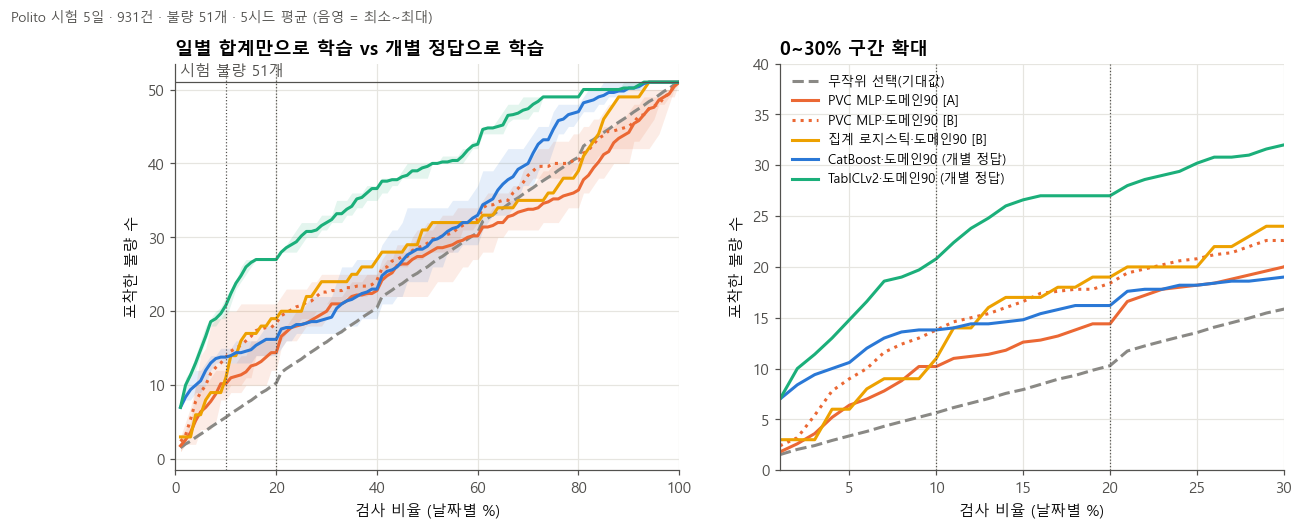

In [6]:
KEY = [("무작위 선택(기대값)", P.GRAY, "--"), ("PVC MLP·도메인90 [A]", P.PAL[1], "-"), ("PVC MLP·도메인90 [B]", P.PAL[1], ":"),
       ("집계 로지스틱·도메인90 [B]", P.PAL[3], "-"), ("CatBoost·도메인90 (개별 정답)", P.PAL[0], "-"),
       ("TabICLv2·도메인90 (개별 정답)", P.PAL[2], "-")]
NP = int(yte.sum())
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))
for lab, col, ls in KEY:
    a = agg[agg.모델 == lab]; x = a.budget * 100
    for ax in axes:
        ax.plot(x, a.caught, ls, color=col, label=lab)
    axes[0].fill_between(x, a.lo, a.hi, color=col, alpha=.12, lw=0)
axes[0].axhline(NP, color=P.INK2, lw=.8); axes[0].text(1, NP + .8, f"시험 불량 {NP}개", color=P.INK2)
axes[0].set_xlim(0, 100); axes[1].set_xlim(1, 30); axes[1].set_ylim(0, 40)
for ax in axes:
    ax.set_xlabel("검사 비율 (날짜별 %)"); ax.set_ylabel("포착한 불량 수")
    for b in (10, 20): ax.axvline(b, color=P.INK2, lw=.8, ls=":")
axes[0].set_title("일별 합계만으로 학습 vs 개별 정답으로 학습", loc="left", fontweight="bold")
axes[1].set_title("0~30% 구간 확대", loc="left", fontweight="bold")
axes[1].legend(loc="upper left", fontsize=8.5)
fig.suptitle("Stellantis N.V. 시험 5일 · 931건 · 불량 51개 · 5시드 평균 (음영 = 최소~최대)", x=0.01, ha="left", color=P.INK2, fontsize=9)
P.save(fig, "06_daily_aggregate_budget"); plt.show()

## 4. 그림 — 날짜별 실제 불량 수와 집계 모델의 추정

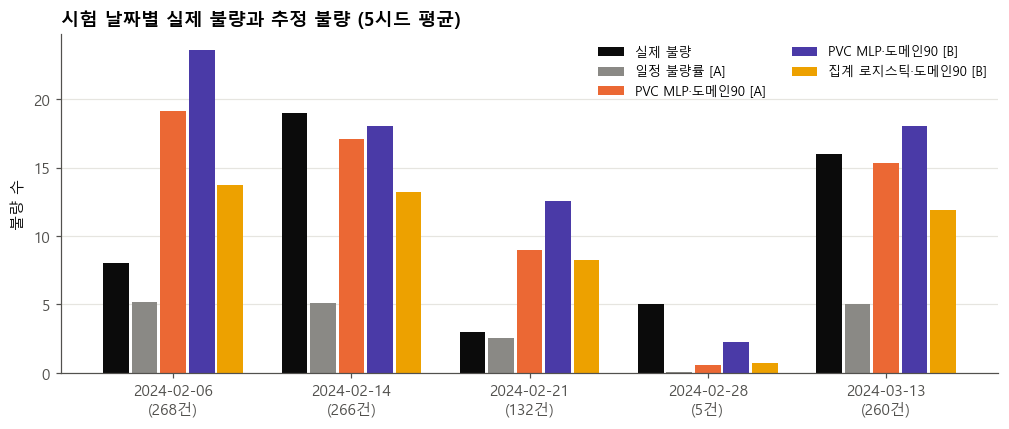

In [7]:
show = [("A", "일정 불량률", P.GRAY), ("A", "PVC MLP·도메인90", P.PAL[1]), ("B", "PVC MLP·도메인90", P.PAL[6]),
        ("B", "집계 로지스틱·도메인90", P.PAL[3])]
dates = list(yt.index)
fig, ax = plt.subplots(figsize=(11, 4))
w = 0.16; x = np.arange(len(dates))
ax.bar(x - 2 * w, yt.values, w * .9, color=P.INK, label="실제 불량")
for i, (proto, lab, col) in enumerate(show):
    v = daily.loc[(proto, lab), dates].values.astype(float)
    ax.bar(x + (i - 1) * w, v, w * .9, color=col, label=f"{lab} [{proto}]")
n_day = pd.Series(dte).value_counts().loc[dates].values
ax.set_xticks(x); ax.set_xticklabels([f"{dd}\n({n}건)" for dd, n in zip(dates, n_day)])
ax.set_ylabel("불량 수"); ax.grid(axis="x", visible=False); ax.legend(fontsize=8.5, ncol=2)
ax.set_title("시험 날짜별 실제 불량과 추정 불량 (5시드 평균)", loc="left", fontweight="bold")
P.save(fig, "07_daily_counts"); plt.show()